# Days 2–3 — Forecasting a Lorenz 96 ensemble with a quantum algorithm
### Based on Bravyi et al., arXiv:2507.06198 (2025) and arXiv:2606.08349 (2026)

## The mission

A weather centre estimates the uncertainty of a forecast by running an **ensemble**: many forecasts from slightly different starts, with random perturbations, averaged at the end. The *Kolmogorian algorithm* of Bravyi and co-authors claims to compute that ensemble average on a quantum computer without running any ensemble members. In two days your team tests the claim on a toy atmosphere, from the equations to a simulated noisy quantum processor.

**The model.** Stochastic Lorenz 96 with $K = 4$ points on a latitude circle, damping $\lambda = 1$, noise strength $q = 2$, no constant forcing ($F = 0$, which the theory requires):

$$dX_k = \big[X_{k-1}(X_{k+1} - X_{k-2}) - \lambda X_k\big]\,dt + \sqrt{q}\,dW_k .$$

**The forecast question.** Start with an anomaly of 1.5 at sites 0 and 2, $x = 1.5\,(e_0 + e_2)$. Predict the ensemble mean at site 1, $\mathbb{E}[X_1(t)]$, for $0 \le t \le 2$. Site 1 is driven only by the product $X_0X_2$, so a linear model predicts nothing here: the answer comes entirely from the nonlinearity.

**The referee.** A 100,000-member Monte Carlo ensemble, computed below. Every number you produce is compared with it.

## Plan for two days

| When | Stage | You have it when |
|---|---|---|
| Day 2 morning | **1. Equations → matrices** | The automatic checks pass for 2 and 4 levels per site |
| Day 2 afternoon | **2. The forecast, computed exactly** | Your forecast agrees with Monte Carlo, and you know how many qubits that takes |
| Day 3 morning | **3. The forecast, computed by a circuit** | A gate circuit reproduces Stage 2, and you can say which error is left |
| Day 3, early afternoon | **4. The circuit on noisy spin qubits** | You can say how good the qubits must be for the circuit to stay useful |
| Day 3, late afternoon | **Report and pitch** | Report table filled, 5-minute pitch |

Checkpoints with a supervisor: end of Stage 1, end of Day 2, end of Stage 3. If a stage runs more than an hour over, ask for help; it is better to finish Stage 4 with help than to stop at Stage 2.

**Working as three.** Every stage has a part that can be done in parallel: someone writes the next function, someone writes its test or plot, someone reads ahead in the primer or the papers. Rotate, so that each of you can explain every stage in the pitch.

**How this notebook works.** Each stage gives the background, the functions to write (name, inputs, outputs), and checks that tell you when they are right. *How* to write them is up to you. Hints are folded under each stage; open them when you are stuck. **Rules:** quote the Monte Carlo standard error next to every comparison, and say which error you are looking at (truncation, Trotter, hardware noise, or sampling).

In [3]:
import numpy as np, math, time, warnings
import scipy.sparse as sp
from scipy.linalg import expm
from scipy.sparse.linalg import expm_multiply, svds
from scipy.special import gammaln
from numpy.polynomial.hermite_e import hermeval
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from qiskit import QuantumCircuit
from qiskit.circuit.library import StatePreparation, PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp, Statevector, DensityMatrix

from spin_pulse import HardwareSpecs, Shape, ExperimentalEnvironment, PulseCircuit, DynamicalDecoupling
from spin_pulse.environment.noise import NoiseType

COL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'lines.linewidth': 2, 'font.size': 10})
print("Imports OK.")

Imports OK.


## Primer: the five ideas you need

Read this together before starting (about 30 minutes). Each idea is used in one stage.

**1. The ensemble mean obeys a linear equation (Stage 1).** For a stochastic equation $dX = f(X)\,dt + \sqrt q\,dW$, the ensemble mean of an observable, $v(t, x) = \mathbb{E}[u_0(X(t)) \mid X(0) = x]$, satisfies the *backward Kolmogorov equation*

$$\partial_t v = f(x)\cdot\nabla v + \tfrac q2\,\Delta v, \qquad v(0, x) = u_0(x).$$

It is a linear PDE, even when $f$ is nonlinear. The price is that $v$ lives on the whole state space. Example: for $f(x) = -\lambda x$ and $u_0 = x$, the solution is $v = x\,e^{-\lambda t}$, and the noise drops out of the mean.

**2. An oscillator basis turns the PDE into a matrix (Stage 1).** Expand $v$ in Hermite functions of each variable. In that basis, multiplying by $x$ and differentiating become combinations of the creation and annihilation operators $a^\dagger$, $a$ of a quantum harmonic oscillator. Basis state $|n\rangle$ means "Hermite function of degree $n$", or "$n$ quanta". The Kolmogorov equation becomes $d\psi/dt = (-\Lambda + C)\,\psi$: $\Lambda$ (damping) counts quanta, $C$ (nonlinearity) moves them between sites. On a computer the basis is cut at $d$ levels, $n = 0, \dots, d-1$.

**3. Several sites means a tensor product (Stage 1).** With $K$ sites, a basis state is a list of occupation numbers $|m_0, m_1, \dots, m_{K-1}\rangle$, so there are $d^K$ states. With $d$ a power of 2, that is $K\log_2 d$ qubits. An operator acting on site $i$ only is $\mathbb 1\otimes\cdots\otimes a\otimes\cdots\otimes\mathbb 1$ (Kronecker product, `np.kron` or `scipy.sparse.kron`).

**4. Unitary parts become circuits (Stage 3).** $C$ is skew-Hermitian ($C^\dagger = -C$), so $e^{Ct}$ is unitary and can be built from gates. Write $iC = \sum_k c_k P_k$ with Pauli strings $P_k$ (such as `XZIY`). Each $e^{-ic_kP_k\delta t}$ is a standard gate sequence. Multiplying them in turn over small steps $\delta t$ approximates $e^{Ct}$: this is a *Trotter* product, with an error that shrinks like $\delta t$. The damping $e^{-\Lambda t}$ is not unitary; here you apply it classically.

**5. Noisy qubits give mixed states (Stage 4).** A noisy processor outputs a density matrix $\rho$ instead of a state vector. Two numbers describe it: **purity** $\mathrm{Tr}\,\rho^2$ (1 for a pure state) and **fidelity** $\langle\psi_{\rm ideal}|\rho|\psi_{\rm ideal}\rangle$ (1 if it is the right state). Spin qubits lose phase coherence on a time scale $T_2^*$; *spin-echo* pulses undo part of that loss.

The demonstration below shows ideas 2 and 3 on a small example. Run it and read the output.

In [4]:
# Idea 2: one oscillator cut at d = 4 levels. a|n> = sqrt(n)|n-1>, so a has sqrt(1), sqrt(2), sqrt(3) above the diagonal.
d = 4
a = np.diag(np.sqrt(np.arange(1, d)), k=1)
print("a =\n", a.round(3))
print("number operator a†a = diag", np.diag(a.T @ a).round(3), " (counts quanta)")
print("[a, a†] = diag", np.diag(a @ a.T - a.T @ a).round(3), " (1 everywhere except the last level: the price of cutting at d)")

# Idea 3: two sites. The annihilation operator of site 1 is identity ⊗ a.
a_site1 = np.kron(np.eye(d), a)
state = np.zeros(d * d); state[np.ravel_multi_index((0, 2), (d, d))] = 1.0     # |m0 = 0, m1 = 2>
out = a_site1 @ state
print("\na_1 |0, 2> =", [f"{v:.3f} |{tuple(int(m) for m in np.unravel_index(i, (d, d)))}>" for i, v in enumerate(out) if abs(v) > 0], " (= sqrt(2) |0, 1>)")

a =
 [[0.    1.    0.    0.   ]
 [0.    0.    1.414 0.   ]
 [0.    0.    0.    1.732]
 [0.    0.    0.    0.   ]]
number operator a†a = diag [0. 1. 2. 3.]  (counts quanta)
[a, a†] = diag [ 1.  1.  1. -3.]  (1 everywhere except the last level: the price of cutting at d)

a_1 |0, 2> = ['1.414 |(0, 1)>']  (= sqrt(2) |0, 1>)


## The referee: Monte Carlo ensemble (provided)

Two ensembles, because there are two versions of the question:

- **fixed start**: every member starts exactly at $x$;
- **noisy start**: members start at $x + z$, $z \sim \mathcal{N}(0, p)$, $p = q/(2\lambda)$ (2025 paper, Eq. 8). This is the case the paper's cost theorem covers.

Runtime: about one minute. Look at the numbers: what do the two curves do, and why do they differ at $t = 0.25$?

In [5]:
K, LAM, Q = 4, 1.0, 2.0
X_ANOM = np.zeros(K); X_ANOM[[0, 2]] = 1.5
OBS = 1
TIMES = np.linspace(0, 2, 9)          # forecast times; the checkers compare at these times

def l96_drift(X):
    # f_k = X_{k-1}(X_{k+1} - X_{k-2}); X has shape (K, members)
    return np.roll(X, 1, 0) * (np.roll(X, -1, 0) - np.roll(X, 2, 0))

def monte_carlo(x0, obs, times, noisy_start, lam=LAM, q=Q, M=1000, dt=1e-3, seed=0):
    rng = np.random.default_rng(seed)
    X = np.repeat(np.asarray(x0, float)[:, None], M, 1)
    if noisy_start:
        X += rng.normal(0, math.sqrt(q / (2 * lam)), X.shape)
    marks, out = set(np.round(np.asarray(times) / dt).astype(int)), []
    for s in range(int(round(times[-1] / dt)) + 1):
        if s in marks:
            out.append((X[obs].mean(), X[obs].std() / math.sqrt(M)))
        X = X + (l96_drift(X) - lam * X) * dt + math.sqrt(q * dt) * rng.standard_normal(X.shape)
    return np.array(out)

t0 = time.time()
mc_noisy = monte_carlo(X_ANOM, OBS, TIMES, noisy_start=True)
mc_fixed = monte_carlo(X_ANOM, OBS, TIMES, noisy_start=False)
print(f"Monte Carlo done in {time.time() - t0:.0f} s")
print("t            :", TIMES)
print("E[X1], noisy :", mc_noisy[:, 0].round(4), "  max s.e.", mc_noisy[:, 1].max().round(4))
print("E[X1], fixed :", mc_fixed[:, 0].round(4), "  max s.e.", mc_fixed[:, 1].max().round(4))

Monte Carlo done in 1 s
t            : [0.   0.25 0.5  0.75 1.   1.25 1.5  1.75 2.  ]
E[X1], noisy : [-0.008   0.2921  0.3307  0.2637  0.1894  0.1156  0.0845  0.064   0.0355]   max s.e. 0.0347
E[X1], fixed : [0.     0.3449 0.4165 0.347  0.256  0.1668 0.1238 0.0885 0.0457]   max s.e. 0.0329


## Toolbox (provided)

Run this cell. The tools check your work or handle plumbing (Qiskit and SpinPulse conventions); none of them does a stage for you.

| Tool | Stage | What it does |
|---|---|---|
| `check_tensor(c)` | 1 | Checks your coupling tensor against the Lorenz 96 equations and the paper's conditions |
| `check_generator(Lambda, C, K, d)` | 1 | Checks your damping and nonlinearity matrices, including a fingerprint of $C$ that does not depend on how you order the basis |
| `hermite_function(n, y)` | 2 | $h_n(y) = \mathrm{He}_n(y)/\sqrt{n!}$ |
| `check_forecast(times, values, start)` | 2, 3 | Compares a forecast with the matching Monte Carlo ensemble, in units of its standard error |
| `plot_forecast(curves, start)` | 2, 3 | Plots your curves over the Monte Carlo reference |
| `pauli_decomposition(C)` | 3 | Pauli strings $P_k$ and coefficients $c_k$ with $iC = \sum_k c_kP_k$ |
| `trotter_numpy(op, t, reps, psi)` | 3 | The same product of Pauli rotations as a Qiskit circuit, applied directly to a vector: fast at 8 qubits |
| `spinpulse_channel(circuit, t2s, use_dd)` | 4 | Runs a circuit through SpinPulse's spin-qubit noise model; returns the averaged channel and the compiled circuit |

In [19]:
# Fingerprints of C for K = 4, per-site cutoff d, lam = 1, q = 2: (Frobenius norm, largest singular value).
# Both scale with sqrt(q / (2 lam)) and do not depend on the basis ordering.
_C_REF = {2: (5.6568542495, 2.4494897428), 3: (36.0, 9.2505136235), 4: (117.5755076536, 21.1684691783),
          5: (282.8427124746, 37.93434009), 6: (569.2099788303, 59.05283841)}

def _flag(ok):
    return "PASS " if ok else "CHECK"

def check_tensor(c, K=K):
    """c: dict {(i, j, k): value} or array of shape (K, K, K), meaning f_i(x) = sum_jk c_ijk x_j x_k."""
    if isinstance(c, dict):
        T = np.zeros((K, K, K))
        for (i, j, k), v in c.items():
            T[i, j, k] += v
    else:
        T = np.asarray(c, float)
    x = np.random.default_rng(1).standard_normal(K)
    drift_ok = np.allclose(np.einsum('ijk,j,k->i', T, x, x), l96_drift(x[:, None])[:, 0])
    sym = np.abs(T - T.transpose(0, 2, 1)).max()
    Ts = 0.5 * (T + T.transpose(0, 2, 1))
    diag = max(abs(Ts[i, j, j]) + abs(Ts[j, i, j]) + abs(Ts[j, j, i]) for i in range(K) for j in range(K))
    cyc = np.abs(Ts + Ts.transpose(1, 2, 0) + Ts.transpose(2, 0, 1)).max()
    print(f"{_flag(drift_ok)} reproduces the Lorenz 96 drift at a random state")
    print(f"{_flag(sym < 1e-12)} symmetric in the last two indices (max asymmetry {sym:.1e})")
    print(f"{_flag(diag < 1e-12)} no f_i contains x_i          (max |c_ijj|+|c_jij|+|c_jji| = {diag:.1e})")
    print(f"{_flag(cyc < 1e-12)} c_ijk + c_jki + c_kij = 0     (max {cyc:.1e}; 2025 paper, Eq. 4)")
    print(f"      J = max |c_ijk| = {np.abs(Ts).max():g};  nonzeros per slice c_i.. = {max(int((Ts[i] != 0).sum()) for i in range(K))}")

def check_generator(Lambda, C, K=K, d=None, lam=LAM, q=Q):
    """Lambda, C: dense or sparse matrices on the truncated space. d: levels per site (per-site cutoff)."""
    L, Cs = sp.csr_matrix(Lambda), sp.csr_matrix(C)
    dim = Cs.shape[0]
    skew = abs(Cs + Cs.conj().T).max() if Cs.nnz else 0.0
    print(f"{_flag(skew < 1e-10)} C is skew-Hermitian, so exp(Ct) is unitary  (||C + C†||max = {skew:.1e})")
    offdiag = abs(L - sp.diags(L.diagonal())).max() if L.nnz else 0.0
    print(f"{_flag(offdiag < 1e-12)} Lambda is diagonal")
    if d is not None and dim == d**K:
        n = np.zeros(1)
        for _ in range(K):
            n = np.add.outer(n, np.arange(d)).ravel()
        ok = np.allclose(np.sort(L.diagonal().real), np.sort(lam * n))
        print(f"{_flag(ok)} Lambda = lam x (total number of quanta) on every basis state")
    if dim <= 1024:
        H = (-L + Cs).toarray()
        top = np.linalg.eigvals(H).real.max()
        print(f"{_flag(top < 1e-8)} no growing modes: max Re eig(-Lambda + C) = {top:.1e}")
    if d in _C_REF and dim == d**K:
        scale = math.sqrt(q / (2 * lam))
        fro_ref, sv_ref = (v * scale for v in _C_REF[d])
        fro = sp.linalg.norm(Cs)
        sv = np.linalg.svd(Cs.toarray(), compute_uv=False)[0] if dim <= 1024 else svds(Cs, k=1, return_singular_vectors=False)[0]
        ok = abs(fro - fro_ref) < 1e-6 * fro_ref and abs(sv - sv_ref) < 1e-5 * sv_ref
        print(f"{_flag(ok)} fingerprint of C: ||C||_F = {fro:.4f} (reference {fro_ref:.4f}), "
              f"largest singular value = {sv:.4f} (reference {sv_ref:.4f})")
        if not ok:
            ratio = fro / fro_ref
            print(f"      ratio to reference = {ratio:.4f}. A constant ratio hints at a prefactor; "
                  "otherwise check which operators enter T and how c is symmetrized.")
    else:
        print("      no stored fingerprint for this truncation; structural checks only")

def check_forecast(times, values, start="noisy", label="your forecast"):
    """times: subset of TIMES; values: E[X1] at those times; start: 'noisy' or 'fixed'."""
    mc = mc_noisy if start == "noisy" else mc_fixed
    times, values = np.atleast_1d(times), np.atleast_1d(np.real(values))
    idx = [int(np.argmin(abs(TIMES - t))) for t in times]
    if any(abs(TIMES[i] - t) > 1e-9 for i, t in zip(idx, times)):
        raise ValueError("compare at times contained in TIMES")
    dev = values - mc[idx, 0]
    se = mc[idx, 1].max()
    worst = np.abs(dev).max()
    verdict = "consistent with Monte Carlo" if worst <= 3 * se else "differs from Monte Carlo"
    print(f"{_flag(worst <= 3 * se)} {label} ({start} start): max |forecast - MC| = {worst:.4f} "
          f"= {worst / se:.1f} s.e. (s.e. {se:.4f}) -> {verdict}")
    return worst

def plot_forecast(curves, start="noisy", ax=None, title=None):
    """curves: dict {label: (times, values)}. Draws them over the Monte Carlo mean ± 2 s.e."""
    mc = mc_noisy if start == "noisy" else mc_fixed
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    ax.errorbar(TIMES, mc[:, 0], yerr=2 * mc[:, 1], fmt='o', color='k', ms=4, label="Monte Carlo ±2 s.e.")
    for (lab, (t, v)), col in zip(curves.items(), COL):
        ax.plot(t, np.real(v), '-' if len(t) > 5 else 's', color=col, label=lab)
    ax.set_xlabel("t"); ax.set_ylabel(r"$\mathbb{E}[X_1(t)]$"); ax.legend(frameon=False, fontsize=8)
    ax.set_title(title or f"{start} start", loc='left')
    return ax

def pauli_decomposition(C) -> SparsePauliOp:
    """Pauli strings P_k and real c_k with iC = sum_k c_k P_k (C skew-Hermitian, dimension a power of 2)."""
    dense = C.toarray() if sp.issparse(C) else np.asarray(C)
    p = SparsePauliOp.from_operator(1j * dense)
    return SparsePauliOp(p.paulis, coeffs=p.coeffs.real)

def trotter_numpy(op: SparsePauliOp, t: float, reps: int, psi: np.ndarray) -> np.ndarray:
    """reps repetitions of prod_k exp(-i c_k P_k t/reps), in the order of op: the same product a circuit
    of single-term PauliEvolutionGates applies. Since iC = sum_k c_k P_k, this approximates exp(Ct) psi."""
    mats = [(c.real, SparsePauliOp([P]).to_matrix(sparse=True)) for P, c in zip(op.paulis, op.coeffs)]
    dt, psi = t / reps, np.asarray(psi, complex)
    for _ in range(reps):
        for c_k, P_k in mats:
            psi = math.cos(c_k * dt) * psi - 1j * math.sin(c_k * dt) * (P_k @ psi)
    return psi

def spinpulse_channel(circuit: QuantumCircuit, t2s: float, use_dd: bool = False, noise_type=NoiseType.PINK,
                      num_samples: int = 4, env_duration: int = 2**18):
    """Noise-averaged channel of the WHOLE circuit (including any state preparation inside it) on SpinPulse's
    spin-qubit model. Returns (channel, transpiled circuit). Gate counts: transpiled.count_ops().
    Runtime: tens of seconds per call at 4-6 qubits. Call np.random.seed(...) first for reproducible noise.
    Known bug (spin-pulse 1.1.3): use_dd=True can raise ValueError on some circuits."""
    n = circuit.num_qubits
    hs = HardwareSpecs(n, 0.5, 0.2, 0.01, Shape.GAUSSIAN, ramp_duration=5,
                       dynamical_decoupling=DynamicalDecoupling.SPIN_ECHO if use_dd else None, optim=3)
    isa = hs.gate_transpile(circuit)
    seg = 1 if noise_type == NoiseType.WHITE else env_duration
    env = ExperimentalEnvironment(hardware_specs=hs, noise_type=noise_type, T2S=t2s,
                                  duration=env_duration, segment_duration=seg)
    channel = PulseCircuit.from_circuit(isa, hs, exp_env=env).mean_channel(env, num_samples=num_samples, progress_bar=False)
    return channel, isa

def hermite_function(n: int, y):
    """h_n(y) = He_n(y) / sqrt(n!), with He_n the probabilists' Hermite polynomial (He_0 = 1, He_1 = y, He_2 = y^2 - 1, ...)."""
    coeffs = np.zeros(n + 1); coeffs[n] = 1.0
    return hermeval(y, coeffs) / math.exp(0.5 * gammaln(n + 1))

print("Toolbox loaded.")

Toolbox loaded.


---
## Stage 1 — Equations → matrices (Day 2 morning)

**Background.** The 2025 paper covers equations of the form $dX_i = \big(-\lambda X_i + \sum_{j,k} c_{ijk} X_jX_k\big)dt + \sqrt q\,dW_i$. In the oscillator basis (primer, ideas 2–3) their Kolmogorov equation becomes $d\psi/dt = (-\Lambda + C)\,\psi$ with

$$\Lambda = \lambda\sum_i a_i^\dagger a_i, \qquad C = T - T^{\top}, \qquad T = \sqrt{q/2}\;\lambda^{-1/2}\sum_{ijk} c_{ijk}\,a_j^\dagger a_k^\dagger a_i \quad (\text{2026 paper, Eq. 30}).$$

Reading $T$: it removes one quantum from site $i$ and adds one at site $j$ and one at site $k$, with weight $c_{ijk}$.

**Functions to write**

| Function | Returns |
|---|---|
| `l96_tensor(K)` | dict `{(i, j, k): c_ijk}` with $\sum_{jk} c_{ijk}x_jx_k = x_{i+1}x_{i-1} - x_{i-2}x_{i-1}$ (indices mod $K$), symmetric in $j, k$ |
| `annihilation(d)` | the $d\times d$ matrix $a$ |
| `site_operator(op, i, K, d)` | sparse matrix of `op` acting on site $i$ of $K$ |
| `build_generator(K, d, lam, q)` | `(Lambda, C)` as sparse matrices of size $d^K$ |

**You have it when** `check_tensor` passes, and `check_generator` passes for $d = 2$ and $d = 4$.

**Questions** (keep short answers for the pitch).
1. How many states and qubits does $K = 4$ need at $d = 2$, 4 and 8? How many Pauli strings are in $C$ at $d = 2$ and $d = 4$? (`len(pauli_decomposition(C))`)
2. `check_tensor` tests two conditions of the paper. Show on paper that they mean (i) no $f_i$ contains $x_i$ and (ii) $\sum_i x_if_i = 0$. Which physical property is (ii)? Why would a constant forcing $F$ break it?
3. In $C$, the factor $\sqrt q$ multiplies the physical nonlinearity. Why does more noise make the nonlinearity look *stronger* in oscillator units? (Hint: what is the oscillator's natural length scale?)

<details><summary>Hint: the tensor</summary>

A product $x_ax_b$ can be split as $\tfrac12$ into `c[(i, a, b)]` and $\tfrac12$ into `c[(i, b, a)]`. Remember Python's `%` for periodic indices: `(i - 2) % K`.
</details>

<details><summary>Hint: site operators</summary>

Start from `sp.identity(1)` and loop over the $K$ sites, Kronecker-multiplying by `op` at site $i$ and by `sp.identity(d)` elsewhere. Check on $d = 3$, $K = 2$ against the primer's `np.kron`.
</details>

<details><summary>Hint: building C</summary>

With `a = [site_operator(annihilation(d), i, K, d) for i in range(K)]` and `ad = [x.T for x in a]`, each term of $T$ is `v * ad[j] @ ad[k] @ a[i]`. Writing $C = T - T^\top$ makes $C$ exactly skew-symmetric, even after the cut at $d$ levels.
</details>

In [7]:
# Stage 1: your functions.

def l96_tensor(K):
    c = {}
    for i in range(K):
        for j, k, w in [((i + 1) % K, (i - 1) % K, 0.5),
                        ((i - 2) % K, (i - 1) % K, -0.5)]:
            c[(i, j, k)] = c.get((i, j, k), 0) + w
            c[(i, k, j)] = c.get((i, k, j), 0) + w
    return c



In [8]:
# Stage 1: checks (run when your functions are ready)
def l96_tensor(K):
    """{(i, j, k): c_ijk} avec sum_jk c_ijk x_j x_k = x_{i+1} x_{i-1} - x_{i-2} x_{i-1}, symétrique en (j, k)."""
    c = {}
    for i in range(K):
        for j, k, w in [((i + 1) % K, (i - 1) % K, 0.5),
                        ((i - 2) % K, (i - 1) % K, -0.5)]:
            c[(i, j, k)] = c.get((i, j, k), 0) + w
            c[(i, k, j)] = c.get((i, k, j), 0) + w
    return c
 
 
def annihilation(d):
    """a|n> = sqrt(n)|n-1> : sqrt(1..d-1) au-dessus de la diagonale."""
    return sp.diags(np.sqrt(np.arange(1, d)), 1, format='csr')
 
 
def site_operator(op, i, K, d):
    """op agissant sur le site i parmi K (site 0 = facteur de gauche du Kronecker)."""
    out = sp.identity(1, format='csr')
    for s in range(K):
        out = sp.kron(out, op if s == i else sp.identity(d), format='csr')
    return out
 
 
def build_generator(K, d, lam, q):
    """(Lambda, C), matrices creuses d^K x d^K. Lambda = lam * sum a†a ; C = T - T^T,
    T = sqrt(q/2) lam^(-1/2) sum_ijk c_ijk a_j† a_k† a_i."""
    a = [site_operator(annihilation(d), i, K, d) for i in range(K)]
    ad = [x.T.tocsr() for x in a]
    pref = math.sqrt(q / 2) / math.sqrt(lam)
    dim = d ** K
    T = sp.csr_matrix((dim, dim))
    for (i, j, k), v in l96_tensor(K).items():
        if v != 0:
            T = T + pref * v * (ad[j] @ ad[k] @ a[i])
    C = (T - T.T).tocsr()
    Lambda = lam * sum((ad[i] @ a[i] for i in range(K)), sp.csr_matrix((dim, dim)))
    return Lambda.tocsr(), C

---
## Stage 2 — The forecast, computed exactly (Day 2 afternoon)

**Background.** In oscillator units each variable is $y_k = x_k\sqrt{2\lambda/q}$, and basis state $|\mathbf m\rangle = |m_0,\dots,m_{K-1}\rangle$ stands for the function $\prod_k h_{m_k}(y_k)$, $h_n = \mathrm{He}_n/\sqrt{n!}$. Three ingredients turn the matrices of Stage 1 into a forecast:

- **The initial state $\psi(0)$** encodes the observable, $u_0(x) = x_1$. Since $\mathrm{He}_1(y) = y$, we have $x_1 = \sqrt p\,h_1(y_1)$ with $p = q/(2\lambda)$: the state is $\sqrt p$ times "one quantum on site 1".
- **Evolution:** $\psi(t) = e^{t(-\Lambda + C)}\,\psi(0)$, computed exactly with SciPy here (Stage 3 replaces it by a circuit).
- **Readout.** For a **fixed start** $x$, the forecast is $v(t, x) = \sum_{\mathbf m}\psi_{\mathbf m}(t)\prod_k h_{m_k}(y_k)$: the overlap of $\psi(t)$ with a readout vector. For a **noisy start** $x + z$, $z \sim \mathcal N(0, p)$ (the case the paper's theorems cover, 2025, Eqs. 8 and 72–74), average over $z$. In $y$ units the noise $Z$ is standard Gaussian, and $\mathbb E_Z[\mathrm{He}_n(y + Z)] = y^n$. For example, $\mathbb E[(y+Z)^2 - 1] = y^2 + 1 - 1 = y^2$. So the noisy-start readout vector has entries $\prod_k y_k^{m_k}/\sqrt{m_k!}$, and nothing else changes.

**Functions to write**

| Function | Returns |
|---|---|
| `initial_state(K, d, site, lam, q)` | vector of length $d^K$ |
| `readout_fixed(K, d, x0, lam, q)`, `readout_noisy(K, d, x0, lam, q)` | vectors of length $d^K$ |
| `forecast_exact(K, d, x0, site, times, readout, lam, q, nonlinear=True)` | $v(t)$ at each time in `times` |

**You have it when**

1. **Sanity check.** With `nonlinear=False` (i.e. $C = 0$), the forecast at site 0 equals $1.5\,e^{-t}$ to about $10^{-12}$, for both readouts. That is the linear example of primer idea 1.
2. `check_forecast` passes for both starts at some $d$; plot $d = 2, 4, 6$ against Monte Carlo with `plot_forecast`.

**Questions.**
1. What is the smallest $d$ that agrees with Monte Carlo, and how many qubits is that?
2. The fixed and noisy starts give different curves. Which question does a weather centre actually ask?
3. Why does the forecast at site 1 rise and then decay? Answer with the model equation, not the code.

<details><summary>Hint: the position of a basis state</summary>

In a Kronecker-ordered vector, the state $|m_0, \dots, m_{K-1}\rangle$ sits at `np.ravel_multi_index((m_0, ..., m_{K-1}), (d,) * K)`. That matches the ordering of `site_operator` if site 0 is the leftmost factor.
</details>

<details><summary>Hint: readout vectors</summary>

Both are Kronecker products over sites of a length-$d$ vector: $[h_0(y_k), \dots, h_{d-1}(y_k)]$ for the fixed start, $[y_k^n/\sqrt{n!}]_{n<d}$ for the noisy start. Build them with a loop of `np.kron`, like the operators.
</details>

<details><summary>Hint: exact evolution at many times</summary>

`expm_multiply(G, psi0, start=times[0], stop=times[-1], num=len(times), endpoint=True)` returns the state at every time in one call; `G` must be sparse (`.tocsc()`). The forecast is then `states @ readout_vector`.
</details>

In [37]:
# Stage 2: your functions.
def initial_state(K, d, site, lam, q):
    psi = np.zeros(d**K)
    m = np.zeros(K, dtype=int); m[site] = 1
    psi[np.ravel_multi_index(m, (d,) * K)] = math.sqrt(q / (2 * lam))
    return psi

def _kron_over_sites(vectors):
    out = np.array([1.0])
    for v in vectors:
        out = np.kron(out, v)
    return out

def readout_fixed(K, d, x0, lam, q):
    y = np.asarray(x0, float) * math.sqrt(2 * lam / q)
    return _kron_over_sites([[hermite_function(n, yk) for n in range(d)] for yk in y])

def readout_noisy(K, d, x0, lam, q):
    y = np.asarray(x0, float) * math.sqrt(2 * lam / q)
    return _kron_over_sites([[yk**n / math.sqrt(math.factorial(n)) for n in range(d)] for yk in y])

def forecast_exact(K, d, x0, site, times, readout, lam=LAM, q=Q, nonlinear=True):
    Lambda, Cmat = build_generator(K, d, lam, q)
    G = (-Lambda + (Cmat if nonlinear else 0 * Cmat)).tocsc()
    states = expm_multiply(G, initial_state(K, d, site, lam, q), start=times[0], stop=times[-1],
                           num=len(times), endpoint=True)
    return states @ readout(K, d, x0, lam, q)

In [38]:
# Stage 2: sanity check, comparison with Monte Carlo, plot
v = forecast_exact(4, 3, X_ANOM, 0, TIMES, readout_noisy, LAM, Q, nonlinear=False); print(np.abs(v - 1.5 * np.exp(-TIMES)).max())
check_forecast(TIMES, forecast_exact(4, 4, X_ANOM, OBS, TIMES, readout_noisy, LAM, Q), start="noisy")
check_forecast(TIMES, forecast_exact(4, 4, X_ANOM, OBS, TIMES, readout_fixed, LAM, Q), start="fixed")

3.3306690738754696e-16
PASS  your forecast (noisy start): max |forecast - MC| = 0.0287 = 0.8 s.e. (s.e. 0.0347) -> consistent with Monte Carlo
PASS  your forecast (fixed start): max |forecast - MC| = 0.0641 = 1.9 s.e. (s.e. 0.0329) -> consistent with Monte Carlo


np.float64(0.06409085747117593)

---
## Stage 3 — The forecast, computed by a circuit (Day 3 morning)

**Background.** Replace the exact $e^{C\,\delta t}$ by a gate circuit (primer, idea 4), and apply the damping classically around it. One time step $\delta t$ is

$$e^{-\Lambda\delta t/2}\;\; e^{C\delta t}\;\; e^{-\Lambda\delta t/2}.$$

Because $\Lambda$ is diagonal, $e^{-\Lambda\delta t/2}$ just multiplies each amplitude by $e^{-\lambda|\mathbf m|\delta t/2}$, where $|\mathbf m|$ is its number of quanta. In Qiskit, `PauliEvolutionGate(SparsePauliOp([P], [c]), time=dt)` applies $e^{-icP\,dt}$; since $iC = \sum_k c_kP_k$, a product of these over all terms approximates $e^{C\,dt}$.

**Functions to write**

| Function | Returns |
|---|---|
| `trotter_circuit(op, t, reps)` | Qiskit circuit: `reps` repetitions of one `PauliEvolutionGate` per Pauli term, each for time `t/reps` |
| `forecast_circuit(K, d, x0, site, times, steps_per_unit, readout)` | the forecast with damping + circuit steps |

**You have it when**

1. **Convergence plot** at $d = 2$ (4 qubits): $\|\psi_{\rm circuit} - e^{Ct}\psi\|$ against `reps` = 1, 2, 4, …, 64 on log–log axes. Which slope do you expect?
2. **Forecast plot:** circuit forecast at $d = 2$ and $d = 4$ (32 steps per time unit), together with your Stage 2 curves and Monte Carlo.
3. **Error split at $t = 1$:** truncation error (Stage 2 vs Monte Carlo) and Trotter error (circuit vs Stage 2), for $d = 2$ and $d = 4$. Which one dominates in each case?

**Speed warning.** At $d = 4$ (8 qubits) $C$ has 512 Pauli strings, and Qiskit simulating them gate by gate takes minutes per step. Use the Qiskit circuit at $d = 2$. At $d = 4$, use `trotter_numpy(op, dt, 1, psi)`, which applies exactly the same rotations to a vector; check that it agrees with your circuit at $d = 2$ first.

<details><summary>Hint: comparing states</summary>

A global phase does not change a forecast, but it does change $\|\psi_{\rm circuit} - \psi_{\rm exact}\|$. Multiply the circuit state by `np.exp(-1j * np.angle(np.vdot(exact, circuit_state)))` before comparing. For the initial state, `qc.initialize(psi0 / norm, range(n))` prepares a normalized vector.
</details>

<details><summary>Hint: one damped step with a circuit</summary>

Qiskit's `Statevector` needs a normalized vector, but the damping shrinks the norm. Store the norm, normalize, evolve with `Statevector(psi / nrm).evolve(step_circuit).data`, then multiply by `nrm`.
</details>

<details><summary>Hint: why one gate per term</summary>

A single `PauliEvolutionGate` for the whole sum may be compiled exactly, which hides the Trotter error you are asked to measure.
</details>

# Comment fonctionne la décomposition utilisée dans le Stage 3

## 1. Le problème

Au Stage 1, on a construit $G = -\Lambda + C$, où $\Lambda$ est diagonale (amortissement) et $C$ est **antihermitienne** ($C^\dagger = -C$). La partie qui nous intéresse pour le circuit est

$$e^{Ct}\,\psi_0 .$$

Comme $C^\dagger=-C$, cette matrice est **unitaire**. Mais un ordinateur quantique ne sait pas appliquer « une matrice $d^K\times d^K$ » : il sait appliquer des portes à 1 ou 2 qubits. Il faut donc écrire $e^{Ct}$ comme un produit de portes simples. Cela se fait en trois étapes.

```
C  ──(Pauli)──►  Σ c_k P_k  ──(Trotter)──►  Π exp(−i c_k dt P_k)  ──(portes)──►  H/Rx/Ry, CNOT, Rz
```

## 2. Étape 1 : décomposition de Pauli

### La base de Pauli

Pour $n$ qubits, une **chaîne de Pauli** est un produit tensoriel
$P = \sigma_{n-1}\otimes\dots\otimes\sigma_0$ avec $\sigma\in\{I,X,Y,Z\}$. Il y en a $4^n$. Elles forment une base orthogonale de l'espace des matrices $2^n\times 2^n$ :

$$\mathrm{Tr}(P_j P_k) = 2^n\,\delta_{jk}.$$

Toute matrice $M$ s'écrit donc de façon unique $M=\sum_k c_k P_k$, avec

$$c_k = \frac{\mathrm{Tr}(P_k M)}{2^n}.$$

### Pourquoi on décompose $iC$ et non $C$

$C$ est antihermitienne, donc $iC$ est **hermitienne**. Pour une matrice hermitienne, tous les $c_k$ sont **réels** (car $\mathrm{Tr}(PM)^* = \mathrm{Tr}(MP) = \mathrm{Tr}(PM)$). On écrit

$$iC = \sum_k c_k P_k \quad\Longrightarrow\quad C = -i\sum_k c_k P_k \quad\Longrightarrow\quad e^{Ct} = e^{-i\,t\sum_k c_k P_k}.$$

C'est une exponentielle de la forme « $e^{-iHt}$ », un hamiltonien $H=\sum_k c_kP_k$, que l'on sait simuler.

### Taille du problème

Le nombre de qubits est $n = K\log_2 d$. Le nombre de chaînes de Pauli non nulles dans $C$ vaut **8** pour $d=2$ ($n=4$) et **512** pour $d=4$ ($n=8$). Ce nombre croît vite avec $d$ et fixe le coût du circuit.

### Convention de Qiskit

Dans un label comme `IXXY`, le caractère de **gauche** agit sur le qubit $n-1$ et celui de droite sur le qubit 0. L'indice $i$ d'un vecteur de base $|i\rangle$ a le qubit 0 pour bit de poids faible. C'est pourquoi l'état rangé avec le site 0 à gauche du produit de Kronecker est déjà dans le bon ordre, sans permutation.

## 3. Étape 2 : l'approximation de Trotter

On voudrait écrire $e^{-it\sum_k c_kP_k}=\prod_k e^{-itc_kP_k}$. Ce n'est vrai que si les $P_k$ **commutent**, ce qui n'est pas le cas ici. La formule de Trotter d'ordre 1 le remplace par une approximation. On découpe $t$ en $r$ pas, avec $dt=t/r$ :

$$e^{-i\,dt\sum_k c_kP_k}\;\approx\;\prod_k e^{-i\,c_k\,dt\,P_k},
\qquad
e^{Ct}\approx\Big(\prod_k e^{-ic_k\,dt\,P_k}\Big)^{r}.$$

- **Erreur par pas** : de l'ordre de $\tfrac12\|[A,B]\|\,dt^2$ pour deux termes $A$, $B$.
- **Erreur totale** après $r=t/dt$ pas : de l'ordre de $dt$. Si l'on double le nombre de pas, l'erreur est divisée par ~2. C'est ce qu'on observe sur la courbe de convergence (pente 1 en log-log).
- **Chaque facteur est unitaire**, donc le produit l'est aussi exactement. L'erreur ne porte pas sur la norme de l'état, mais sur sa direction.

Chaque facteur $e^{-i\theta P}$, avec $\theta=c_k\,dt$, vaut, puisque $P^2=I$,

$$e^{-i\theta P}=\cos\theta\; I - i\sin\theta\; P .$$

C'est la formule utilisée par `trotter_numpy` et `trotter_exponentials`.

## 4. Étape 3 : une exponentielle de Pauli devient des portes (`apply_pauli_rotation`)

Soit $S$ l'ensemble des qubits où $P\neq I$, avec $m=|S|$ éléments.

**a) Changement de base.** Sur chaque qubit de $S$, on applique une rotation $R$ telle que $R P_q R^\dagger = Z$ :

| Pauli | Rotation $R$ (avant) | Rotation inverse (après) |
|---|---|---|
| $X$ | `ry(−π/2)` | `ry(+π/2)` |
| $Y$ | `rx(+π/2)` | `rx(−π/2)` |
| $Z$ | rien | rien |

Avec $V=\bigotimes R_q$, on a $VPV^\dagger=Z^{\otimes m}$, donc

$$e^{-i\theta P}=V^\dagger\, e^{-i\theta Z^{\otimes m}}\,V .$$

**b) $e^{-i\theta Z^{\otimes m}}$ avec des CNOT.** La matrice $Z^{\otimes m}$ est diagonale : sur $|b_1\dots b_m\rangle$, sa valeur propre est $(-1)^{b_1\oplus\dots\oplus b_m}$, la **parité** des bits. Une échelle de CNOT (`cx(q₁,q₂)`, `cx(q₂,q₃)`, ...) range cette parité dans le dernier qubit. Une seule porte $R_z(\alpha)=e^{-i\alpha Z/2}$ avec $\alpha=2\theta$ ajoute alors la phase $e^{-i\theta(-1)^{\text{parité}}}$, ce qui est exactement l'action voulue. On défait ensuite l'échelle (un CNOT est son propre inverse).

*Exemple* ($P=Z\otimes Z$) : `cx(0,1)`, `rz(2θ)` sur le qubit 1, `cx(0,1)`.

**c) Cas particulier** : si $P=I$, alors $e^{-i\theta I}=e^{-i\theta}$ est une phase globale (`qc.global_phase -= theta`).

Ce circuit est **exact** pour un terme. La seule approximation de la méthode est l'étape 2, entre les termes.

## 5. L'amortissement $\Lambda$

$\Lambda$ est diagonale mais **non unitaire** ($e^{-\Lambda t}$ réduit la norme), donc ce n'est pas une porte. Dans notre simulation, elle est appliquée **classiquement** sur le vecteur d'état. Comme $\Lambda$ et $C$ ne commutent pas, on utilise un découpage symétrique à chaque pas :

$$e^{(-\Lambda+C)\,dt}\;\approx\;e^{-\Lambda dt/2}\;e^{C\,dt}\;e^{-\Lambda dt/2}.$$

C'est l'option `damping=True` de `evolve_trotter`. Entre deux pas, on renormalise le vecteur avant de le passer à `Statevector`, qui exige une norme 1, puis on remultiplie par la norme.

## 6. Comment vérifier que tout est correct

| Test | Attendu |
|---|---|
| `trotter_numpy` contre `evolve_trotter` (mêmes termes, mêmes pas) | écart $\sim10^{-12}$ ou moins : le circuit réalise exactement le produit de Trotter |
| `evolve_trotter` contre `expm(C·t) @ psi0` pour 4, 8, 16, 32, 64 pas | erreur divisée par ~2 à chaque ligne (pente 1) |
| `C` antihermitienne, `max Re eig(−Λ+C) = 0` | pas de mode croissant |

Si le premier test échoue, cherchez dans l'ordre : l'ordre des termes, la convention de qubits (gauche du label = qubit $n-1$), la phase globale.

In [ ]:
# Stage 3: your functions.
import math
import numpy as np
import scipy.sparse as sp
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

# build_generator(K, d, lam, q) -> (Lambda, C) vient de votre Stage 1.

PAULI = {'I': sp.identity(2, format='csr'),
         'X': sp.csr_matrix([[0, 1], [1, 0]], dtype=complex),
         'Y': sp.csr_matrix([[0, -1j], [1j, 0]], dtype=complex),
         'Z': sp.csr_matrix([[1, 0], [0, -1]], dtype=complex)}


# ---------------------------------------------------------------- 
# 2. exponentielles de Trotter (matrices, pour vérifier)
def pauli_matrix(label):
    M = sp.identity(1, format='csr')
    for ch in label:                      # le caractère de gauche est le facteur de gauche du kron
        M = sp.kron(M, PAULI[ch], format='csr')
    return M

def trotter_exponentials(labels, coeffs, dt):
    """Une exponentielle exp(-i c_k dt P_k) = cos(c_k dt) I - i sin(c_k dt) P_k par terme (P_k^2 = I)."""
    N = 2 ** len(labels[0])
    I = sp.identity(N, format='csr', dtype=complex)
    return [math.cos(c * dt) * I - 1j * math.sin(c * dt) * pauli_matrix(l) for l, c in zip(labels, coeffs)]


# ----------------------------------------------------------------
#  3. Pauli -> Rx, Ry, Rz, CNOT
def apply_pauli_rotation(qc, label, theta):
    """Ajoute à qc la porte exp(-i theta P), P = label (convention Qiskit: label[::-1][q] agit sur le qubit q)."""
    act = {q: ch for q, ch in enumerate(reversed(label)) if ch != 'I'}
    if not act:                                    # chaîne identité : simple phase globale
        qc.global_phase -= theta
        return
    qubits = sorted(act)
    for q in qubits:                               # changement de base : P -> Z
        if act[q] == 'X': qc.ry(-math.pi / 2, q)
        elif act[q] == 'Y': qc.rx(math.pi / 2, q)
    for a, b in zip(qubits[:-1], qubits[1:]):      # échelle de CNOT : parité sur le dernier qubit
        qc.cx(a, b)
    qc.rz(2 * theta, qubits[-1])                   # Rz(a) = exp(-i a Z / 2)
    for a, b in reversed(list(zip(qubits[:-1], qubits[1:]))):
        qc.cx(a, b)
    for q in qubits:                               # retour à la base d'origine
        if act[q] == 'X': qc.ry(math.pi / 2, q)
        elif act[q] == 'Y': qc.rx(-math.pi / 2, q)

def add_trotter_step(qc, labels, coeffs, dt):
    for l, c in zip(labels, coeffs):
        apply_pauli_rotation(qc, l, c * dt)
    return qc


# ---------------------------------------------------------------- 4. circuit élémentaire
def trotter_step_circuit(K, d, dt, lam=1.0, q=2.0,draw_circ=False):
    n = K * int(round(math.log2(d)))
    _, C = build_generator(K, d, lam, q)
    op = pauli_decomposition(C)                       #  SparsePauliOp
    labels = [p.to_label() for p in op.paulis]
    coeffs = op.coeffs.real
    qc = QuantumCircuit(n)
    if draw_circ :
        qc.draw('mpl', fold=-1)
    return add_trotter_step(qc, labels, coeffs, dt)


# ---------------------------------------------------------------- 5. évolution complète
def quanta_count(K, d):
    n = np.zeros(1)
    for _ in range(K):
        n = np.add.outer(n, np.arange(d)).ravel()
    return n

def evolve_trotter(psi, K, d, T, dt, lam=1.0, q=2.0, avec_lambda=False,draw_circ=False):
    """psi (taille d^K) -> état à l'instant T avec T/dt pas de Trotter d'ordre 1.
    damping=True ajoute e^{-Lambda dt/2} avant et après chaque pas (classique)."""
    steps = int(round(T / dt)); dt = T / steps
    step = trotter_step_circuit(K, d, dt, lam, q,draw_circ=draw_circ)
    half = np.exp(-lam * quanta_count(K, d) * dt / 2) if avec_lambda else None
    psi = np.asarray(psi, complex)
    for _ in range(steps):
        if avec_lambda: psi = half * psi
        nrm = np.linalg.norm(psi)                  # Statevector exige une norme 1
        psi = nrm * Statevector(psi / nrm).evolve(step).data
        if avec_lambda: psi = half * psi
    return psi




In [44]:
# TEst
K_test=4
d_test=2
Lam, C = build_generator(K=K_test, d=d_test, lam=1.0, q=2.0)
psi0 = np.random.default_rng(0).standard_normal(d_test**K_test); psi0 /= np.linalg.norm(psi0)
exact = expm(C.toarray() * 1.0) @ psi0
for steps in (4, 8, 16, 32, 64):
    v = evolve_trotter(psi0, 4, 2, T=1.0, dt=1.0 / steps,draw_circ=True)
    print(steps, np.abs(v - exact).max())     # doit être divisé par ~2 à chaque ligne



op = pauli_decomposition(C)
psi0 = np.random.default_rng(0).standard_normal(16)
psi0 /= np.linalg.norm(psi0)
a = trotter_numpy(op, 1.0, 32, psi0)
b = evolve_trotter(psi0, 4, 2, T=1.0, dt=1.0 / 32)
print(np.abs(a - b).max())          # attendu : ~1e-12 

4 0.07930640848661455
8 0.042415735195958176
16 0.021842818005392367
32 0.01107282199994486
64 0.005573325658855849
7.110846302088116e-15


SparsePauliOp(['IXXY', 'IXYX', 'XIXY', 'XXYI', 'XYIX', 'XYXI', 'YIXX', 'YXIX'],
              coeffs=[ 0.5+0.j, -0.5+0.j, -0.5+0.j,  0.5+0.j,  0.5+0.j, -0.5+0.j,  0.5+0.j,
 -0.5+0.j])


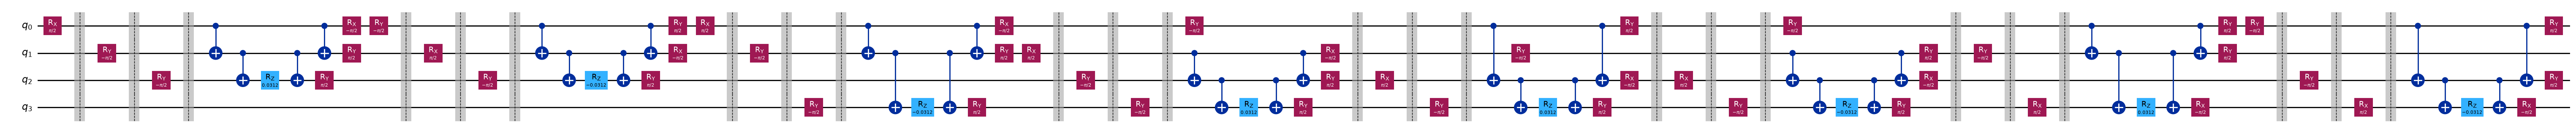

In [42]:
print(op)
trotter_step_circuit(4, 2, 1.0/32).draw('mpl', fold=-1)

## Note importante sur l'implémentation

dans le cas où on fait la multiplication par $\Lambda$ (circuit avec un bruit $q$ moyen), ici on fait avec qiskit.

Il faudrait faire du bloc encoding pour pas perdre l'avantage quantique.

Aussi, en sortie, il faudrait qu'on fasse une méthode avec une mesure de Hamilton (pour avoir direct \<H\>)

## En attendant partie de Adrien

Imaginons qu'on ait N vecteurs X et une fonction
'''python
def X_vers_psi(d,K)
'''
qui nous donne le vecteur psi correspondant.

In [ ]:
from math import factorial
from numpy.polynomial.hermite_e import hermegauss, hermeval


def h(n, y):
    """Fonction de Hermite normalisée : h_n = He_n / sqrt(n!)."""
    return hermeval(y, [0] * n + [1]) / np.sqrt(factorial(n))


def encode(u0, K, d, lam, q, nq=16):
    """Observable u0(x) -> vecteur psi de longueur d^K (coefficients sur prod h_{m_k}(y_k)).
    u0 reçoit x de forme (..., K) et renvoie un tableau de forme (...)."""
    p = q / (2 * lam)
    y, w = hermegauss(nq)                       # points et poids de quadrature
    w = w / np.sqrt(2 * np.pi)
    H = np.array([h(n, y) * w for n in range(d)])               # (d, nq)
    X = np.sqrt(p) * np.stack(np.meshgrid(*[y] * K, indexing="ij"), axis=-1)
    psi = np.broadcast_to(u0(X), (nq,) * K)     # u0 aux points de quadrature
    for ax in range(K):                         # projection sur les h_n, site par site
        psi = np.moveaxis(np.tensordot(H, psi, axes=([1], [ax])), 0, ax)
    return psi.reshape(-1)


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import math
import time
from scipy.linalg import expm

# Paramètres communs
K = 4
LAM = 1.0
Q = 2.0
OBS = 1
X_ANOM = np.zeros(K)
X_ANOM[[0, 2]] = 1.5

TIMES = np.linspace(0, 2, 9)
STEPS_LIST = [4, 8, 16, 32, 64]


# Référence Monte-Carlo
mc = monte_carlo(
    X_ANOM, OBS, TIMES,
    noisy_start=True, M=5000, dt=1e-3, seed=0
)

mc_mean = mc[:, 0]
mc_se = mc[:, 1]


# --------------------------------------------------
# 2. Interface à adapter à ton simulateur quantique
# --------------------------------------------------
def quantum_mean_x1(t, steps, d, K):
    """
    Doit renvoyer <X_1(t)> calculé par la simulation quantique.

    À connecter à evolve_trotter et à ta représentation
    de l'observable X_1 dans l'espace des états psi.

    Convention : OBS=1 correspond à X[1].
    """
    


def compare_steps(d=2, K=4):
    errors = []
    errors_max = []

    for steps in STEPS_LIST:
        q_mean = np.array([
            quantum_mean_x1(t, steps, d, K)
            for t in TIMES
        ])

        diff = np.abs(q_mean - mc_mean)

        # Écart moyen et écart maximal sur les temps observés
        errors.append(np.mean(diff))
        errors_max.append(np.max(diff))

    return np.array(errors), np.array(errors_max)


# Décommenter une fois quantum_mean_x1 implémentée :
#
# errors, errors_max = compare_steps(d=2, K=4)
#
# fig, ax = plt.subplots(figsize=(7, 4))
# ax.plot(STEPS_LIST, errors, "o-", label="Écart moyen")
# ax.plot(STEPS_LIST, errors_max, "s--", label="Écart maximal")
# ax.set_xscale("log", base=2)
# ax.set_yscale("log")
# ax.set_xlabel("Nombre de steps")
# ax.set_ylabel("Écart absolu")
# ax.set_title("Simulation quantique vs Monte-Carlo (K=4, d=2)")
# ax.grid(True, which="both", alpha=0.3)
# ax.legend()
# plt.tight_layout()
# plt.show()


In [13]:
# Stage 3: convergence plot, forecast plot, error split at t = 1

---
## Stage 4 — The circuit on noisy spin qubits (Day 3, early afternoon)

**Background.** SpinPulse simulates a silicon spin-qubit processor at the level of control pulses, including slow ("pink") noise that dephases the qubits on a time scale $T_2^*$ (primer, idea 5). `spinpulse_channel(circuit, t2s, use_dd)` returns the noise-averaged *channel* of your circuit and the compiled circuit; `DensityMatrix(start).evolve(channel)` gives the output $\rho$.

**The circuit to test.** At $d = 2$ (4 qubits): prepare the initial state with `StatePreparation(psi0_normalized)`, then two Trotter steps of $e^{Ct}$ with $t = 0.5$. Its noiseless output `Statevector(circuit).data` is the ideal state.

**Functions to write**

| Function | Returns |
|---|---|
| `noisy_run(circuit, ideal, t2s, use_dd)` | purity, fidelity, and the number of two-qubit (`rzz`) gates of the compiled circuit |

**You have it when** you have one plot of fidelity and purity against $T_2^*$, for $T_2^* = 1{,}000$, $8{,}000$ and $50{,}000$, with and without spin-echo (`use_dd=True`). That is 6 SpinPulse runs, about 20–60 s each, so start them early.

**Questions.**
1. Purity and fidelity measure different things. Which one tells you the forecast is wrong? Find a $T_2^*$ where they disagree.
2. Does spin-echo help? Roughly what $T_2^*$ keeps the fidelity above 0.9, with and without it?
3. Only if time allows: repeat at $K = 5$ or 6 sites without spin-echo. How do the gate count and fidelity change?

<details><summary>Hint: what the channel acts on</summary>

The channel describes the whole circuit, including `StatePreparation`. Apply it to $|0000\rangle$ (`zero = np.zeros(16); zero[0] = 1`), not to the prepared state, or the state gets prepared twice.
</details>

<details><summary>Hint: reproducibility and a known bug</summary>

SpinPulse draws its noise from NumPy's global generator: call `np.random.seed(0)` before a scan, and expect a few percent of scatter between runs. In spin-pulse 1.1.3, `use_dd=True` raises `ValueError: all the input array dimensions…` on some larger circuits (5 or 6 sites). That is a bug in the package, not your mistake: catch it and report the point as missing.
</details>

In [14]:
# Stage 4: your function and the T2* scan

---
## Report and pitch (Day 3, late afternoon)

Fill in for the same forecast, $\mathbb E[X_1(t = 1)]$, noisy start.

| Method | Value | Error vs Monte Carlo | Qubits or ensemble members | Cost (runtime, gates or shots) |
|---|---|---|---|---|
| Monte Carlo ensemble | | ± s.e. | 100,000 members | |
| Exact emulator, smallest $d$ that agrees | | | | |
| Damping + circuit, noiseless, same $d$ | | | | |
| Circuit on SpinPulse (fidelity at your best setting) | — | — | 4 | |

**Pitch, 5 minutes, all three of you speaking.**
1. What does the algorithm compute, and where would it sit in a weather centre's forecasting chain?
2. How close did you get to the ensemble, and which error limited you?
3. What would have to change, in hardware or in the algorithm, for this to be useful to a weather centre?

## Extensions (only if you finish early)

- **Noise strength.** Repeat Stage 2 for $q = 0.5$ and $q = 8$. Which $d$ is needed? The noisy-start readout vector has squared norm $e^{\sum_k y_k^2}$, and the number of measurements needed on hardware grows with it: compute it against $q$.
- **Forcing.** Add a constant forcing $F$ to the Monte Carlo and see how large the disagreement with your $F = 0$ forecast becomes.
- **White noise.** Rerun Stage 4 with `noise_type=NoiseType.WHITE`. Does spin-echo still help? Why not?

## References

- Bravyi, Manson-Sawko, Zayats, Zhuk, *Quantum simulation of a noisy classical nonlinear dynamics*, arXiv:2507.06198 (2025)
- Bravyi, Byrne, Zayats, Zhuk, *Quantum algorithms for stochastic nonlinear differential equations*, arXiv:2606.08349 (2026)
- Lorenz (1996), *Predictability: a problem partly solved*, ECMWF Seminar on Predictability